# Week 4: Benchmarks with costs and lots

Three buy-and-hold benchmarks, all after costs, on the same dates:

1. **LQ45 equal-weight**: every ticker with a price over the whole window
2. **5-ticker equal-weight**: BBCA, BBRI, BMRI, ASII, UNTR (the Week 3 verification set)
3. **IHSG**: the index, bought as if it were a fund

Rules (see `idxlab.backtest.engine`):
- Decide after day 0's close, buy at the **open** of the first later day on which every ticker traded
- Whole lots of 100 shares, leftover cash stays as cash
- Costs from `idxlab.backtest.costs.CostModel` (**placeholder rates until you replace them**)
- Adjusted prices, so returns include dividends. IHSG is a price index and does not, which favors the stocks.
- Sharpe uses a risk-free rate of 0
- `liquidate_at_end=True` sells everything on the last day with sell costs, so results include exit costs

## 1. Load data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from idxlab.backtest.costs import NO_COSTS, CostModel
from idxlab.backtest.engine import prepare_prices, run_buy_and_hold, run_index_buy_and_hold
from idxlab.backtest.metrics import annual_turnover, cagr, max_drawdown, sharpe, total_return

prices = pd.read_parquet("../data/processed/prices.parquet")
print(prices.shape, prices["date"].min().date(), "to", prices["date"].max().date())

ihsg_path = Path("../data/processed/ihsg.parquet")
if ihsg_path.exists():
    ihsg = pd.read_parquet(ihsg_path)
    assert {"date", "open", "close"} <= set(ihsg.columns), "ihsg.parquet needs date, open, close"
    print("IHSG rows:", len(ihsg))
else:
    ihsg = None
    print("No ihsg.parquet yet. Ask Melv for data/processed/ihsg.parquet (date, open, close).")

(46828, 10) 2019-01-01 to 2023-12-29
No ihsg.parquet yet. Ask Melv for data/processed/ihsg.parquet (date, open, close).


## 2. Prepare the universes

The printout here is the universe you report in the README: which recent listings were dropped, and how many dates.

In [2]:
five = prepare_prices(prices, tickers=["BBCA", "BBRI", "BMRI", "ASII", "UNTR"])
lq45 = prepare_prices(prices)

print("LQ45 tickers kept:", lq45.close.shape[1])
print("LQ45 dropped tickers:", lq45.dropped_tickers)
print("LQ45 dropped dates:", lq45.dropped_dates)
print("5-ticker dropped tickers:", five.dropped_tickers)

LQ45 tickers kept: 36
LQ45 dropped tickers: ['ADMR', 'AMMN', 'CUAN', 'GOTO', 'MBMA', 'NCKL', 'PGEO', 'WIFI']
LQ45 dropped dates: 1
5-ticker dropped tickers: []


Put both universes on exactly the same dates.

In [3]:
common = five.close.index.intersection(lq45.close.index)
for d in (five, lq45):
    d.open, d.close, d.volume = d.open.loc[common], d.close.loc[common], d.volume.loc[common]
print(common.min().date(), "to", common.max().date(), "|", len(common), "days")

2019-01-02 to 2023-12-29 | 1218 days


## 3. Run the benchmarks

In [4]:
costs = CostModel()
print(costs)

runs = {
    "LQ45 equal-weight": run_buy_and_hold(lq45, costs=costs, liquidate_at_end=True),
    "5-ticker equal-weight": run_buy_and_hold(five, costs=costs, liquidate_at_end=True),
}
entry = max(r.entry_date for r in runs.values())

if ihsg is not None:
    runs["IHSG"] = run_index_buy_and_hold(
        ihsg, common, entry_date=runs["LQ45 equal-weight"].entry_date,
        costs=costs, liquidate_at_end=True,
    )
print("Stats measured from:", entry.date())

CostModel(buy_fee=0.0015, sell_fee=0.0015, sell_tax=0.001, slippage=0.0005)
Stats measured from: 2019-01-03


In [5]:
def stats(result, start):
    eq = result.equity.loc[start:]
    return {
        "Total return": total_return(eq),
        "CAGR": cagr(eq),
        "Sharpe": sharpe(eq),
        "Max drawdown": max_drawdown(eq),
        "Turnover/yr": annual_turnover(result.trades, eq),
    }


table = pd.DataFrame({name: stats(r, entry) for name, r in runs.items()}).T
table.round(3)

,Total return,CAGR,Sharpe,Max drawdown,Turnover/yr
LQ45 equal-weight,0.708,0.113,0.614,-0.482,0.203
5-ticker equal-weight,0.653,0.106,0.554,-0.443,0.226


## 4. Equity curves

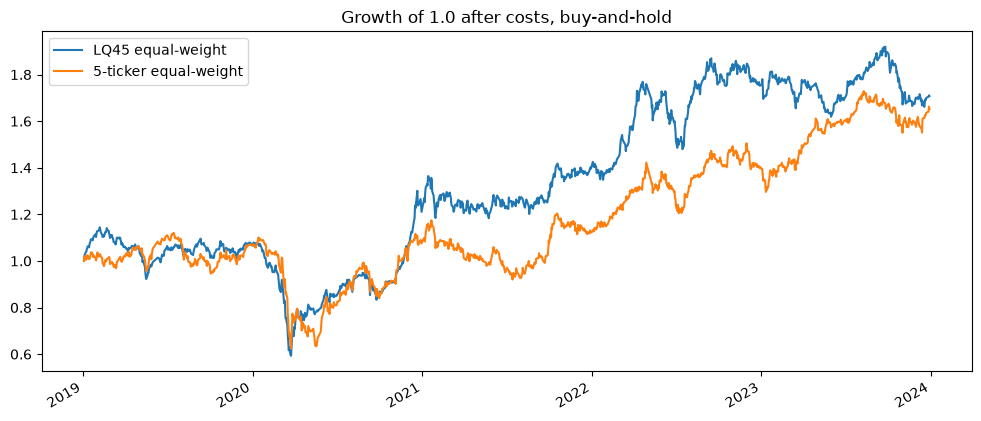

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for name, r in runs.items():
    eq = r.equity.loc[entry:]
    (eq / eq.iloc[0]).plot(ax=ax, label=name)
ax.legend()
ax.set_title("Growth of 1.0 after costs, buy-and-hold")
plt.show()

## 5. Cost drag

Same LQ45 run with and without costs.

In [7]:
free = run_buy_and_hold(lq45, costs=NO_COSTS, liquidate_at_end=True)
paid = runs["LQ45 equal-weight"]

r_free = total_return(free.equity.loc[entry:])
r_paid = total_return(paid.equity.loc[entry:])
print("Total return without costs:", round(r_free, 4))
print("Total return with costs:   ", round(r_paid, 4))
print("Cost drag (percentage points):", round((r_free - r_paid) * 100, 2))
print("Total costs paid (IDR):", round(paid.trades["cost"].sum()))

Total return without costs: 0.713
Total return with costs:    0.7077
Cost drag (percentage points): 0.53
Total costs paid (IDR): 5767505


## 6. Why account size matters (lot rounding)

With a small account split across many stocks, expensive stocks cannot be bought at all.

In [8]:
small = run_buy_and_hold(lq45, initial_capital=20_000_000, costs=costs, liquidate_at_end=True)

big_buys = paid.trades.query("side == 'BUY'")
small_buys = small.trades.query("side == 'BUY'")
print("Lots bought with Rp 1bn: ", int(big_buys["lots"].sum()))
print("Lots bought with Rp 20m: ", int(small_buys["lots"].sum()))
print("Tickers actually bought at Rp 20m:", len(small_buys), "of", lq45.close.shape[1])
print("Total return Rp 1bn:", round(total_return(paid.equity.loc[entry:]), 4))
print("Total return Rp 20m:", round(total_return(small.equity.loc[entry:]), 4))

Lots bought with Rp 1bn:  19308
Lots bought with Rp 20m:  367
Tickers actually bought at Rp 20m: 30 of 36
Total return Rp 1bn: 0.7077
Total return Rp 20m: 0.6268


## Notes (fill in)

- Final numbers for the README table (copy from section 3):
- Which tickers were dropped and why:
- How much did costs reduce the LQ45 return?
- Did LQ45 equal-weight beat IHSG by a wide margin? How much of that could be hindsight bias from using today's LQ45 list on past dates?
- Anything surprising?